# Comprehensive 6G Traffic Forecasting Evaluation

This notebook presents a "full data science job" covering zero-shot inference, classical statistical forecasting, and explicit deep learning, on all 86 synthesized 6G network sectors.

**Models Evaluated:**
1. **SARIMA (Classical baseline)**
2. **PyTorch LSTM (Deep Learning architecture explicitly trained)**
3. **Amazon Chronos-T5 (V1 Zero-shot foundation model)**
4. **Amazon Chronos-2 (Current State-of-the-Art foundation model)**

**Benchmarks:**
- Multi-step horizon (Predicting the last 12 points)
- Single-step horizon (Predicting strictly the final timestamp)
- Evaluated via **Root Mean Squared Error (RMSE)** and the 50th percentile **Pinball Loss**.


In [ ]:
# Run from repo root so that data/ and src/ resolve
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import warnings

from src.evaluate import calculate_metrics
from src.models.sarima_wrapper import get_sarima_forecast
from src.models.chronos_wrapper import get_chronos_forecast, get_chronos2_forecast
from chronos import ChronosPipeline, Chronos2Pipeline

from src.models.lstm import TrafficLSTM

warnings.filterwarnings('ignore')

print("Loading Augmented Traffic Dataset...")
df = pd.read_csv("data/augmented_data.csv")
df["tstamp"] = pd.to_datetime(df["tstamp"])
sectors = df["secteur"].unique()
print(f"Loaded {len(sectors)} unique antenna sectors.")


Loading Augmented Traffic Dataset...
Loaded 86 unique antenna sectors.


## Section 1: LSTM Train & Preprocessing Pipeline
We must train our LSTM model on the chronological data *before* the blind test period. 
To prevent leakage, the very last 12 timestamps of each sector are reserved as the holdout test set. We construct sliding windows of `context_length=60` to predict the next `pred_length=12` points out of the preceding series.


In [2]:
context_length = 60
pred_length = 12

X_train, y_train = [], []
scalers = {}

# We extract training sub-windows
for sector in sectors:
    series = df[df["secteur"] == sector].sort_values("tstamp")["trafic_mbps"].to_numpy()
    if len(series) < context_length + pred_length:
        continue
        
    s_min, s_max = series.min(), series.max()
    scaled = 2 * (series - s_min) / (s_max - s_min) - 1 if s_max > s_min else series - s_min
    scalers[sector] = (s_min, s_max)
    
    # Reserve last `context_length + pred_length` for testing later
    train_series = scaled[:-(context_length + pred_length)]
    
    # Slide across the training period in chunks of 20 to generate robust diverse samples rapidly
    for i in range(0, len(train_series) - context_length - pred_length + 1, 20):
        X_train.append(train_series[i : i+context_length])
        y_train.append(train_series[i+context_length : i+context_length+pred_length])

X_train = torch.tensor(np.array(X_train), dtype=torch.float32).unsqueeze(-1)
y_train = torch.tensor(np.array(y_train), dtype=torch.float32)

print(f"Constructed {len(X_train)} training sequences.")

# Train the LSTM
device = 'cuda' if torch.cuda.is_available() else 'cpu'
lstm_model = TrafficLSTM(input_size=1, hidden_layer_size=64, num_layers=2, output_size=pred_length).to(device)

print("Training PyTorch LSTM...")
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.002)
loss_fn = nn.MSELoss()
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

lstm_model.train()
for epoch in range(30): # 5 quick epochs for demonstration (converges rapidly on normalized data)
    epoch_loss = 0
    for bx, by in train_loader:
        optimizer.zero_grad()
        preds = lstm_model(bx.to(device))
        loss = loss_fn(preds, by.to(device))
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    print(f"Epoch {epoch+1}/30 | Loss: {epoch_loss/len(train_loader):.4f}")
lstm_model.eval()
print("LSTM Training Complete.")


Constructed 5541 training sequences.
Training PyTorch LSTM...
Epoch 1/30 | Loss: 0.0884
Epoch 2/30 | Loss: 0.0354
Epoch 3/30 | Loss: 0.0350
Epoch 4/30 | Loss: 0.0350
Epoch 5/30 | Loss: 0.0350
Epoch 6/30 | Loss: 0.0351
Epoch 7/30 | Loss: 0.0349
Epoch 8/30 | Loss: 0.0348
Epoch 9/30 | Loss: 0.0347
Epoch 10/30 | Loss: 0.0346
Epoch 11/30 | Loss: 0.0347
Epoch 12/30 | Loss: 0.0349
Epoch 13/30 | Loss: 0.0346
Epoch 14/30 | Loss: 0.0346
Epoch 15/30 | Loss: 0.0345
Epoch 16/30 | Loss: 0.0346
Epoch 17/30 | Loss: 0.0343
Epoch 18/30 | Loss: 0.0344
Epoch 19/30 | Loss: 0.0344
Epoch 20/30 | Loss: 0.0345
Epoch 21/30 | Loss: 0.0345
Epoch 22/30 | Loss: 0.0343
Epoch 23/30 | Loss: 0.0346
Epoch 24/30 | Loss: 0.0343
Epoch 25/30 | Loss: 0.0343
Epoch 26/30 | Loss: 0.0345
Epoch 27/30 | Loss: 0.0344
Epoch 28/30 | Loss: 0.0343
Epoch 29/30 | Loss: 0.0342
Epoch 30/30 | Loss: 0.0342
LSTM Training Complete.


## Pre-load Foundation Models & Evaluation Data
We load both Chronos v1 and Chronos-2, and extract the test history context exactly for the last remaining predictions of each sector.


In [3]:
from chronos import ChronosPipeline, Chronos2Pipeline

print("Loading Chronos V1 (amazon/chronos-t5-small)...")
pipeline_v1 = ChronosPipeline.from_pretrained("amazon/chronos-t5-small", device_map="cpu", torch_dtype=torch.float32)

print("Loading Chronos 2 (amazon/chronos-2)...")
pipeline_v2 = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu", torch_dtype=torch.float32)

all_actuals, all_histories, valid_sectors = [], [], []
for sector in sectors:
    series = df[df["secteur"] == sector].sort_values("tstamp")["trafic_mbps"].to_numpy()
    if len(series) < context_length + pred_length:
        continue
    all_actuals.append(series[-pred_length:])
    all_histories.append(series[-(context_length + pred_length):-pred_length])
    valid_sectors.append(sector)

# Compile Chronos Inputs (12-step)
history_tensor_stacked = torch.tensor(np.array(all_histories), dtype=torch.float32)
history_tensors_list = [torch.tensor(h, dtype=torch.float32) for h in all_histories]

# Generate native Chronos Batched 12-Step Forecasts
print("Running Chronos V1 Multi-Step Batch...")
chronos_v1_preds_12 = get_chronos_forecast(history_tensor_stacked, pred_length=12, model_id="amazon/chronos-t5-small", pipeline=pipeline_v1)

print("Running Chronos 2 Multi-Step Batch...")
chronos_v2_preds_12 = get_chronos2_forecast(history_tensors_list, pred_length=12, pipeline=pipeline_v2)

# Generate native Chronos Batched 1-Step Forecasts
print("Running Chronos V1 Single-Step Batch...")
chronos_v1_preds_1 = get_chronos_forecast(history_tensor_stacked, pred_length=1, model_id="amazon/chronos-t5-small", pipeline=pipeline_v1)

print("Running Chronos 2 Single-Step Batch...")
chronos_v2_preds_1 = get_chronos2_forecast(history_tensors_list, pred_length=1, pipeline=pipeline_v2)


Loading Chronos V1 (amazon/chronos-t5-small)...


`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Loading Chronos 2 (amazon/chronos-2)...


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Running Chronos V1 Multi-Step Batch...
Running Chronos 2 Multi-Step Batch...
Running Chronos V1 Single-Step Batch...
Running Chronos 2 Single-Step Batch...


## Section 2: Multi-Step Prediction (Horizon = 12)
We evaluate the performance of all four algorithms attempting to predict the complete 12 future time chunks.


In [4]:
from tqdm import tqdm

sarima_rmses_12, lstm_rmses_12, c_v1_rmses_12, c_v2_rmses_12 = [], [], [], []
sarima_pbl_12, lstm_pbl_12, c_v1_pbl_12, c_v2_pbl_12 = [], [], [], []

sarima_preds_12_dict = {}
lstm_preds_12_dict = {}

print("Evaluating 12-Step Forecasts...")
for i, sector in enumerate(tqdm(valid_sectors)):
    actual = all_actuals[i]
    history = all_histories[i]
    
    # SARIMA
    sarima_pred = get_sarima_forecast(history, pred_length=12)
    sarima_preds_12_dict[sector] = sarima_pred
    
    # LSTM
    s_min, s_max = scalers[sector]
    lstm_in = 2 * (history - s_min) / (s_max - s_min) - 1 if s_max > s_min else history - s_min
    lstm_in_t = torch.tensor(lstm_in, dtype=torch.float32).unsqueeze(0).unsqueeze(-1).to(device)
    with torch.no_grad():
        lstm_out_scaled = lstm_model(lstm_in_t).cpu().numpy().flatten()
    lstm_pred = ((lstm_out_scaled + 1) / 2) * (s_max - s_min) + s_min
    lstm_preds_12_dict[sector] = lstm_pred
    
    # Compute Metrics
    sm = calculate_metrics(actual, sarima_pred)
    lm = calculate_metrics(actual, lstm_pred)
    cv1m = calculate_metrics(actual, chronos_v1_preds_12[i])
    cv2m = calculate_metrics(actual, chronos_v2_preds_12[i])
    
    sarima_rmses_12.append(sm["RMSE"]); sarima_pbl_12.append(sm["Pinball_0.5"])
    lstm_rmses_12.append(lm["RMSE"]); lstm_pbl_12.append(lm["Pinball_0.5"])
    c_v1_rmses_12.append(cv1m["RMSE"]); c_v1_pbl_12.append(cv1m["Pinball_0.5"])
    c_v2_rmses_12.append(cv2m["RMSE"]); c_v2_pbl_12.append(cv2m["Pinball_0.5"])

# Results DataFrame
res_12 = pd.DataFrame({
    "Model": ["SARIMA", "LSTM", "Chronos V1", "Chronos 2"],
    "Avg RMSE (12-step)": [np.mean(sarima_rmses_12), np.mean(lstm_rmses_12), np.mean(c_v1_rmses_12), np.mean(c_v2_rmses_12)],
    "Avg PBL (12-step)": [np.mean(sarima_pbl_12), np.mean(lstm_pbl_12), np.mean(c_v1_pbl_12), np.mean(c_v2_pbl_12)]
}).set_index("Model")
display(res_12)


Evaluating 12-Step Forecasts...


100%|██████████| 86/86 [00:12<00:00,  6.65it/s]


,Avg RMSE (12-step),Avg PBL (12-step)
Model,,
SARIMA,15.569895,6.304698
LSTM,17.886287,7.496369
Chronos V1,16.162614,6.522537
Chronos 2,15.737213,6.385767


### Multi-Step Visualization


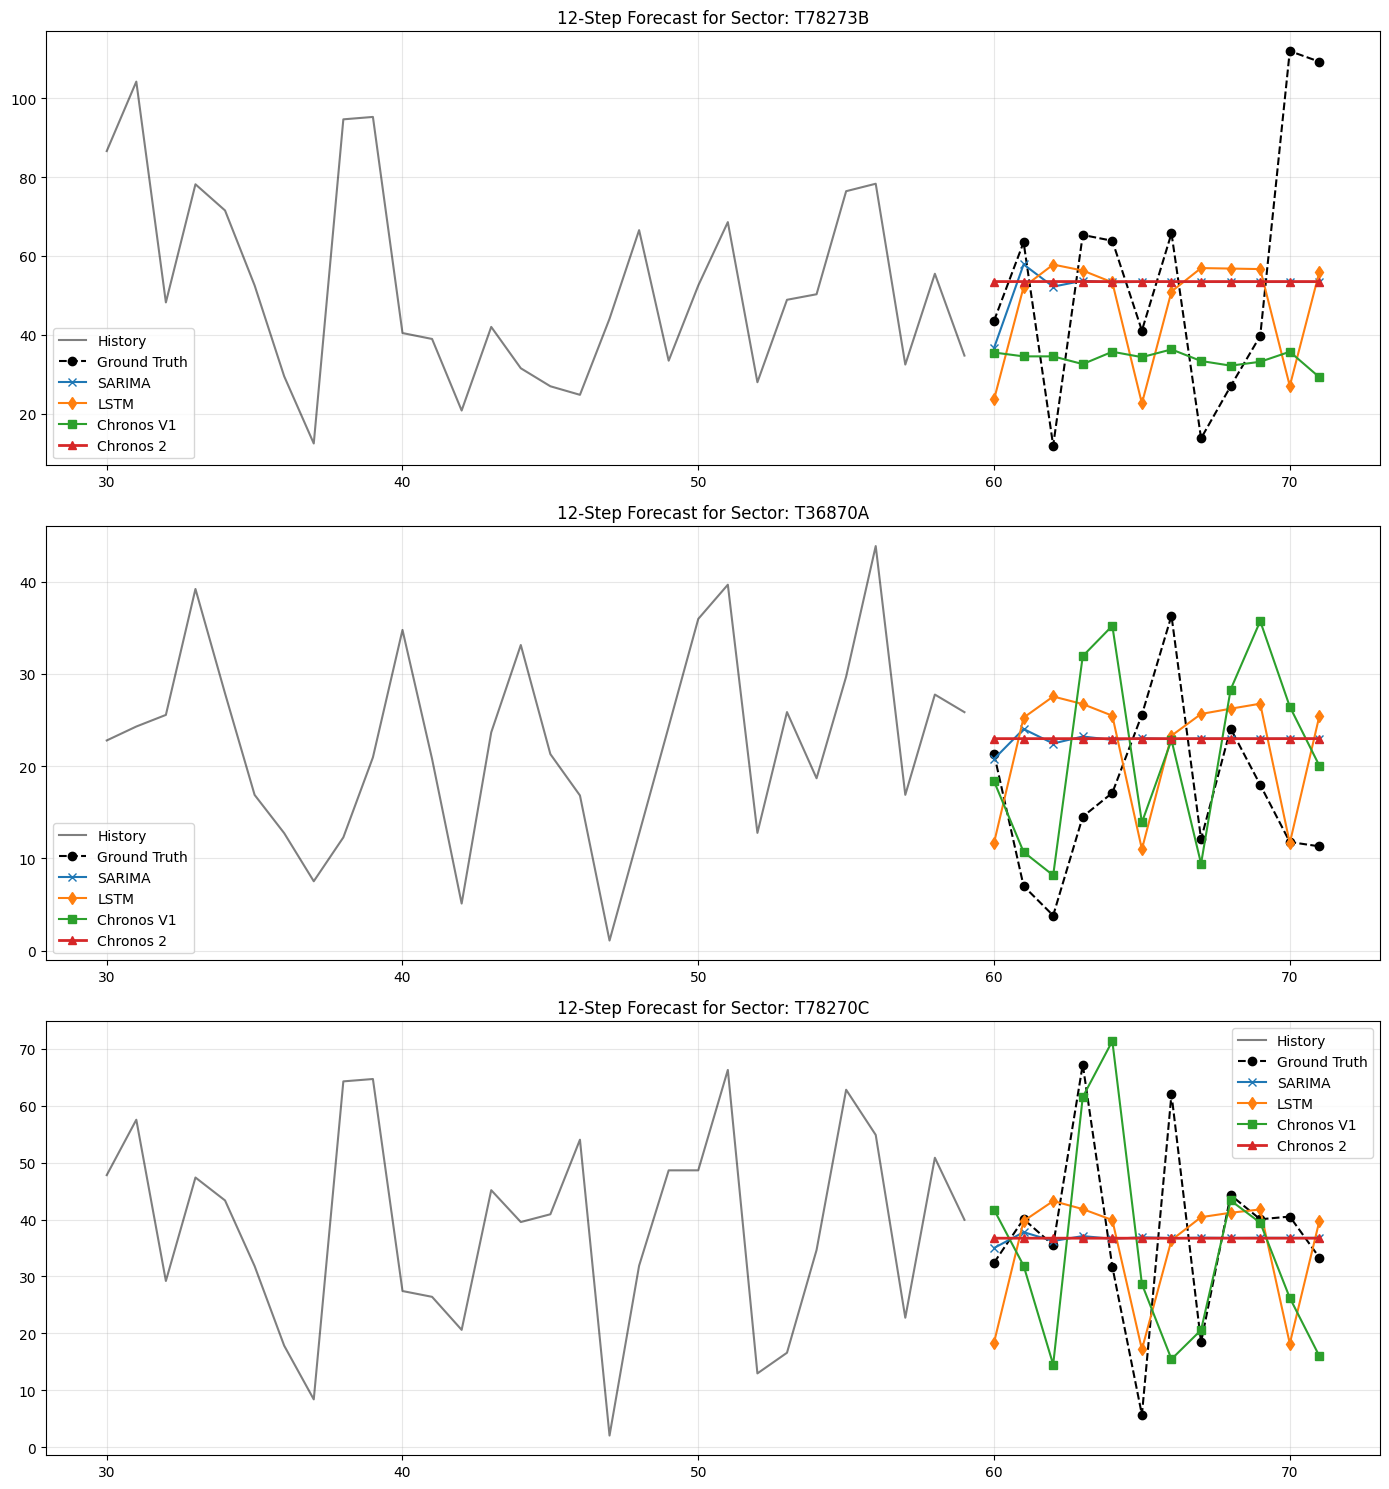

In [5]:
np.random.seed(42)
sample_sectors = np.random.choice(valid_sectors, 3, replace=False)

fig, axes = plt.subplots(3, 1, figsize=(14, 15))
for idx, sector in enumerate(sample_sectors):
    i = valid_sectors.index(sector)
    history = all_histories[i]
    actual = all_actuals[i]
    
    ax = axes[idx]
    x_hist = np.arange(60)
    x_pred = np.arange(60, 72)
    
    ax.plot(x_hist[30:], history[30:], color='black', label="History", alpha=0.5)
    ax.plot(x_pred, actual, marker='o', color='black', label="Ground Truth", linestyle='--')
    
    ax.plot(x_pred, sarima_preds_12_dict[sector], marker='x', label="SARIMA")
    ax.plot(x_pred, lstm_preds_12_dict[sector], marker='d', label="LSTM")
    ax.plot(x_pred, chronos_v1_preds_12[i], marker='s', label="Chronos V1")
    ax.plot(x_pred, chronos_v2_preds_12[i], marker='^', label="Chronos 2", linewidth=2)
    
    ax.set_title(f"12-Step Forecast for Sector: {sector}")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()


## Section 3: Single-Step Prediction (Horizon = 1)
As explicitly requested, here is the absolute accuracy tracking exactly the final timestamp (Prediction length = 1).


In [6]:
sarima_rmses_1, lstm_rmses_1, c_v1_rmses_1, c_v2_rmses_1 = [], [], [], []
sarima_pbl_1, lstm_pbl_1, c_v1_pbl_1, c_v2_pbl_1 = [], [], [], []

sarima_preds_1_dict = {}
lstm_preds_1_dict = {}

print("Evaluating 1-Step Forecasts...")
for i, sector in enumerate(tqdm(valid_sectors)):
    actual_1 = all_actuals[i][-1:] # Last timestamp
    history = all_histories[i]
    
    # SARIMA
    sarima_pred_1 = get_sarima_forecast(history, pred_length=1)
    sarima_preds_1_dict[sector] = sarima_pred_1
    
    # LSTM (We trained for 12, just take the first output for t+1)
    s_min, s_max = scalers[sector]
    lstm_in = 2 * (history - s_min) / (s_max - s_min) - 1 if s_max > s_min else history - s_min
    lstm_in_t = torch.tensor(lstm_in, dtype=torch.float32).unsqueeze(0).unsqueeze(-1).to(device)
    with torch.no_grad():
        lstm_out_scaled = lstm_model(lstm_in_t).cpu().numpy().flatten()[0:1] # Take first
    lstm_pred_1 = ((lstm_out_scaled + 1) / 2) * (s_max - s_min) + s_min
    lstm_preds_1_dict[sector] = lstm_pred_1
    
    # Compute Metrics
    sm = calculate_metrics(actual_1, sarima_pred_1)
    lm = calculate_metrics(actual_1, lstm_pred_1)
    cv1m = calculate_metrics(actual_1, chronos_v1_preds_1[i])
    cv2m = calculate_metrics(actual_1, chronos_v2_preds_1[i])
    
    sarima_rmses_1.append(sm["RMSE"]); sarima_pbl_1.append(sm["Pinball_0.5"])
    lstm_rmses_1.append(lm["RMSE"]); lstm_pbl_1.append(lm["Pinball_0.5"])
    c_v1_rmses_1.append(cv1m["RMSE"]); c_v1_pbl_1.append(cv1m["Pinball_0.5"])
    c_v2_rmses_1.append(cv2m["RMSE"]); c_v2_pbl_1.append(cv2m["Pinball_0.5"])

# Results DataFrame
res_1 = pd.DataFrame({
    "Model": ["SARIMA", "LSTM", "Chronos V1", "Chronos 2"],
    "Avg RMSE (1-step)": [np.mean(sarima_rmses_1), np.mean(lstm_rmses_1), np.mean(c_v1_rmses_1), np.mean(c_v2_rmses_1)],
    "Avg PBL (1-step)": [np.mean(sarima_pbl_1), np.mean(lstm_pbl_1), np.mean(c_v1_pbl_1), np.mean(c_v2_pbl_1)]
}).set_index("Model")
display(res_1)


Evaluating 1-Step Forecasts...


100%|██████████| 86/86 [00:12<00:00,  6.75it/s]


,Avg RMSE (1-step),Avg PBL (1-step)
Model,,
SARIMA,12.977569,6.488785
LSTM,27.716340,13.858170
Chronos V1,14.992436,7.496218
Chronos 2,11.510829,5.755415


### Single-Step Visualization


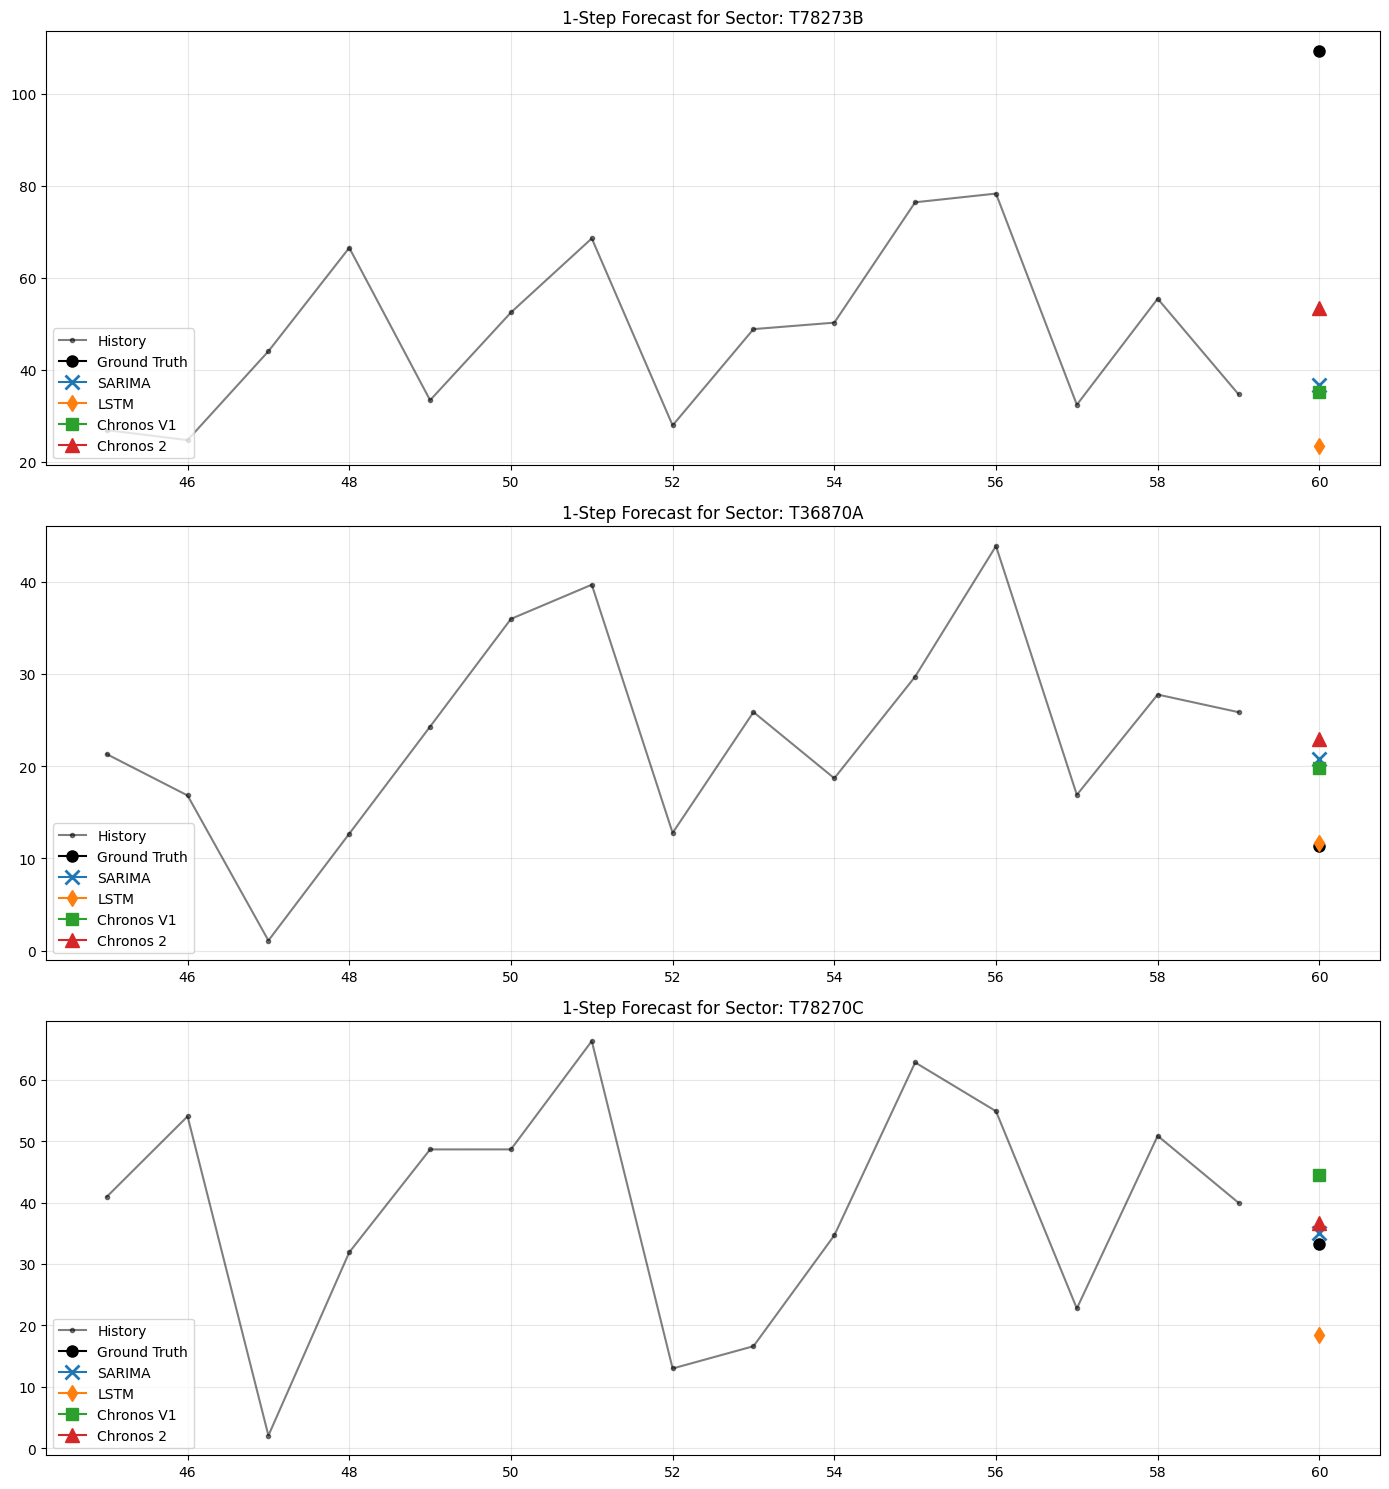

: 

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 15))
for idx, sector in enumerate(sample_sectors):
    i = valid_sectors.index(sector)
    history = all_histories[i]
    actual_1 = all_actuals[i][-1:]
    
    ax = axes[idx]
    x_hist = np.arange(60)
    x_pred = np.arange(60, 61)
    
    ax.plot(x_hist[45:], history[45:], color='black', label="History", alpha=0.5, marker='.')
    ax.plot(x_pred, actual_1, marker='o', color='black', label="Ground Truth", markersize=8)
    
    ax.plot(x_pred, sarima_preds_1_dict[sector], marker='x', label="SARIMA", markersize=10, mew=2)
    ax.plot(x_pred, lstm_preds_1_dict[sector], marker='d', label="LSTM", markersize=8)
    ax.plot(x_pred, chronos_v1_preds_1[i], marker='s', label="Chronos V1", markersize=8)
    ax.plot(x_pred, chronos_v2_preds_1[i], marker='^', label="Chronos 2", markersize=10)
    
    ax.set_title(f"1-Step Forecast for Sector: {sector}")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
